# How closely did the June cash forecast track the bank balance?
Predict each daily closing balance for June 2025 using only statement entries known by 31 May. The EUR 2,500 opening balance precedes the first booking. This backtest evaluates the application's statement-only forecast on the sample business.

In [1]:
from datetime import date
from decimal import Decimal
from pathlib import Path
import sys
import socket
import pandas as pd
import matplotlib.pyplot as plt

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/cfo').is_dir())
sys.path.insert(0, str(root / 'src'))
from cfo.ingestion import parse_statement
from cfo.finance import balance_as_of, build_liquidity_forecast, daily_balances
from cfo.monthly_forecast import project

rows = parse_statement((root / 'data/sample/pizzeria-amalfi-2025.csv').read_bytes())
cutoff = date(2025, 5, 31)
opening = Decimal('2500.00')
training = [r for r in rows if max(r.booked_on, r.value_on) <= cutoff]
print(f'Kernel host: {socket.gethostname()} | Training rows: {len(training)} | Cut-off: {cutoff}')

Kernel host: cfo-forecast-lab-0 | Training rows: 507 | Cut-off: 2025-05-31


In [2]:
cash = balance_as_of(training, opening, cutoff)
flows, (window, weighted), folds, _ = project(training, cutoff, 30)
forecast = build_liquidity_forecast(as_of=cutoff, opening_balance=cash, planned_flows=flows, horizon_days=30)
print(f'Starting cash: EUR {cash:,.2f} | Selected window: {window} month(s) | Recency weighted: {weighted} | Validation months: {folds}')

Starting cash: EUR 2,006.31 | Selected window: 6 month(s) | Recency weighted: False | Validation months: 4


## Forecast versus booked cash
The benchmark carries the 31 May balance forward unchanged. Both forecasts are scored against the same 30 daily closing balances.

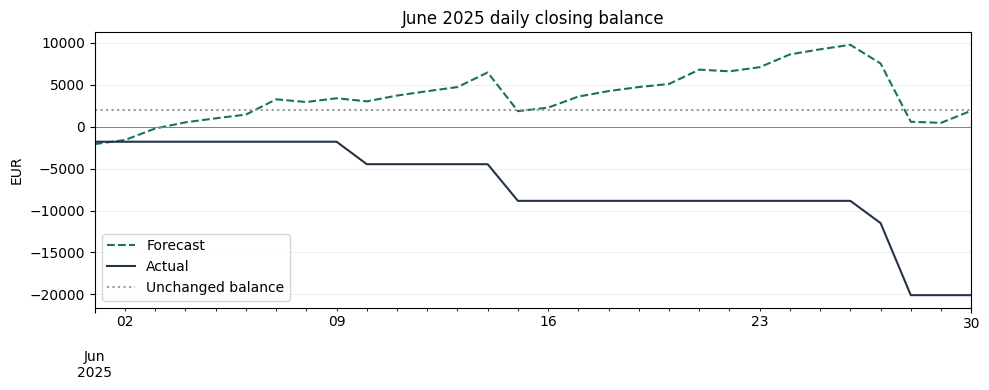

In [3]:
actual = {p.day: p.balance for p in daily_balances(rows, opening)}
days = [p.day for p in forecast.daily_balances]
assert days == list(pd.date_range('2025-06-01', '2025-06-30').date)
daily = pd.DataFrame({
    'Forecast': [float(p.balance) for p in forecast.daily_balances],
    'Actual': [float(actual[d]) for d in days],
    'Unchanged balance': float(cash),
}, index=pd.to_datetime(days))
ax = daily.plot(figsize=(10, 4), color=['#17735c', '#253347', '#999999'], style=['--', '-', ':'])
ax.axhline(0, color='gray', linewidth=0.7)
ax.set(title='June 2025 daily closing balance', ylabel='EUR', xlabel='')
ax.grid(axis='y', alpha=.2)
plt.tight_layout()
plt.show()

In [4]:
for name in ['Forecast', 'Unchanged balance']:
    error = daily[name] - daily['Actual']
    print(f'{name}: mean absolute daily error EUR {error.abs().mean():,.2f}')
error = daily['Forecast'] - daily['Actual']
print(f'Largest absolute error: EUR {error.abs().max():,.2f} on {error.abs().idxmax().date()}')
print(f'30 June: forecast EUR {daily.Forecast.iloc[-1]:,.2f}, actual EUR {daily.Actual.iloc[-1]:,.2f}')
print(f'Days below zero: predicted {(daily.Forecast < 0).sum()}, observed {(daily.Actual < 0).sum()}')

Forecast: mean absolute daily error EUR 10,943.32
Unchanged balance: mean absolute daily error EUR 9,222.67
Largest absolute error: EUR 22,006.21 on 2025-06-30
30 June: forecast EUR 1,907.52, actual EUR -20,098.69
Days below zero: predicted 3, observed 30


This measures one held-out month for one business. The absolute error describes the size of a typical daily balance miss in euros. Other periods and businesses can have different results.